In [51]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import seaborn as sns

# Exemplo 1

In [52]:
# Exemplo: Amostra aleatória cuja distribução é a exponencial

In [53]:
dados_e = np.random.exponential(1, 100)

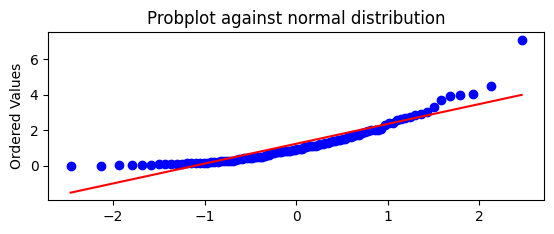

In [54]:
#Gráfico QQ-Plot
fig = plt.figure()
ax1 = fig.add_subplot(211)
prob = stats.probplot(dados_e, dist=stats.norm, plot=ax1)
ax1.set_xlabel('')
ax1.set_title('Probplot against normal distribution')
plt.show()

In [55]:
#A distribuição não é normal

In [56]:
# teste Shapiro Wilks
shapiro=stats.shapiro(dados_e)
shapiro

ShapiroResult(statistic=0.8369023620456431, pvalue=4.00752722507772e-09)

In [57]:
# pvalue<0.05 => distribuição não é normal

In [58]:
#Aplicando a transformacão Box-Cox
y_e, lmax_mle = stats.boxcox(dados_e)
lmax_pearsonr = stats.boxcox_normmax(dados_e)

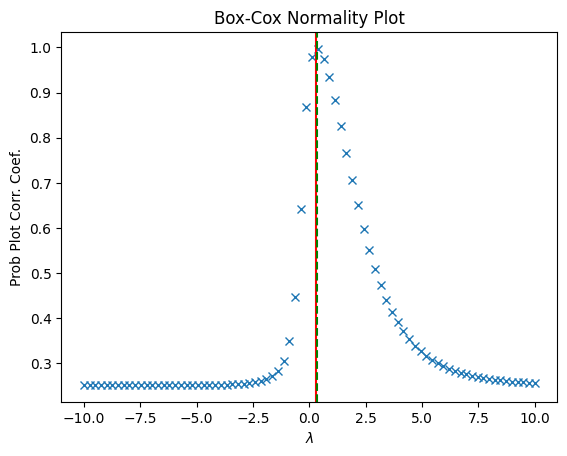

In [59]:
#Gráfico da função L(lambda)
fig = plt.figure()
ax = fig.add_subplot(111)
prob = stats.boxcox_normplot(dados_e, -10, 10, plot=ax)
ax.axvline(lmax_mle, color='r')
ax.axvline(lmax_pearsonr, color='g', ls='--')
plt.show()

Text(0.5, 1.0, 'Probplot after Box-Cox transformation')

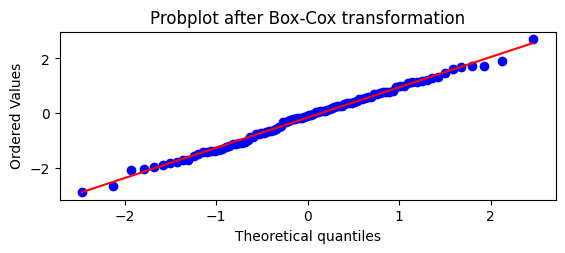

In [60]:
#Gráfico QQ-Plot após a aplicação da transformação
fig = plt.figure()
ax2 = fig.add_subplot(212)
prob = stats.probplot(y_e, dist=stats.norm, plot=ax2)
ax2.set_title('Probplot after Box-Cox transformation')

In [61]:
#A distribuição é normal

In [62]:
# teste Shapiro Wilks
shapiro=stats.shapiro(y_e)
shapiro

ShapiroResult(statistic=0.9940911041129874, pvalue=0.9443272490504494)

In [63]:
# pvalue>0.05 => distribuição é normal

/tmp/ipykernel_7117/3532537497.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(dados_e, hist = False, kde = True,
/home/pedro/Codes/data-science-techniques/.venv/lib/python3.11/site-packages/seaborn/distributions.py:2496: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  kdeplot(**{axis: a}, ax=ax, color=kde_color, **kde_kws)
/tmp/ipykernel_7117/3532537497.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level functio

Lambda value used for Transformation: 0.30990359044388566


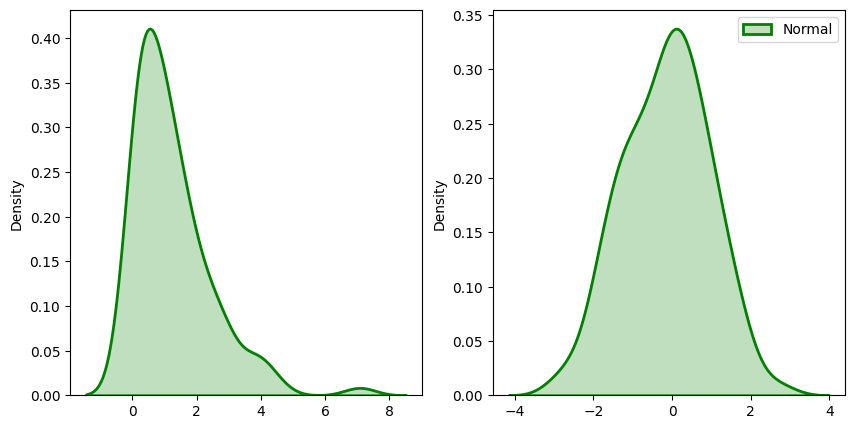

In [64]:
fig, ax = plt.subplots(1, 2)

# plotando os dados originais antes da transformação e os dados transformados
sns.distplot(dados_e, hist = False, kde = True,
            kde_kws = {'shade': True, 'linewidth': 2},
            label = "Non-Normal", color ="green", ax = ax[0])

sns.distplot(y_e, hist = False, kde = True,
            kde_kws = {'shade': True, 'linewidth': 2},
            label = "Normal", color ="green", ax = ax[1])

# adding legends to the subplots
plt.legend(loc = "upper right")

# rescaling the subplots
fig.set_figheight(5)
fig.set_figwidth(10)

print(f"Lambda value used for Transformation: {lmax_mle}")

# Exemplo 2

In [65]:
df = pd.read_excel('./data/class-5-example.xlsx')

In [66]:
x=df.x
y_ex2=df.y

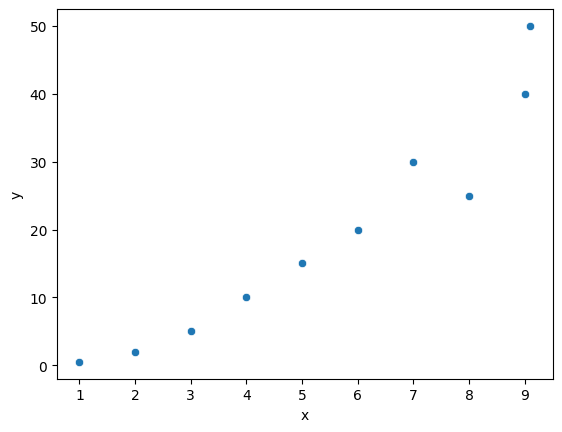

In [67]:
sns.scatterplot(x=df.x, y = df.y)
plt.show()

In [68]:
#Aplicando a transformação Box-Cox
y_t, lmax_mle2 = stats.boxcox(y_ex2)

In [69]:
lmax_mle2

0.42316758311853003

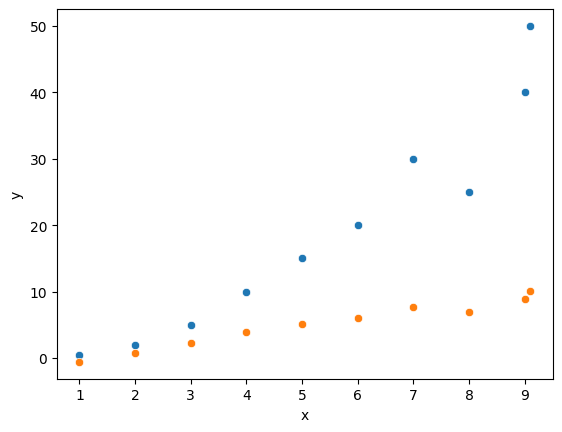

In [70]:
sns.scatterplot(x=df.x, y = y_ex2)
sns.scatterplot(x=df.x, y = y_t)
plt.show()

In [71]:
res_ex2 = stats.linregress(x, y_ex2)
res_ex2

LinregressResult(slope=5.470923345179623, intercept=-9.847695297421758, rvalue=0.9524869212204716, pvalue=2.1049957656312494e-05, stderr=0.618525015003633, intercept_stderr=3.7511897653047996)

In [72]:
res_t = stats.linregress(x, y_t)
res_t

LinregressResult(slope=1.1853858347522515, intercept=-1.3247809315588146, rvalue=0.9844485738732027, pvalue=2.5114878470621113e-07, stderr=0.07478710821950138, intercept_stderr=0.4535639272860908)

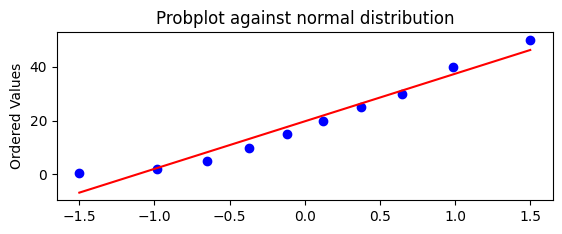

In [73]:
#Gráfico QQ-Plot
fig = plt.figure()
ax1 = fig.add_subplot(211)
prob = stats.probplot(y_ex2, dist=stats.norm, plot=ax1)
ax1.set_xlabel('')
ax1.set_title('Probplot against normal distribution')
plt.show()

Text(0.5, 1.0, 'Probplot after Box-Cox transformation')

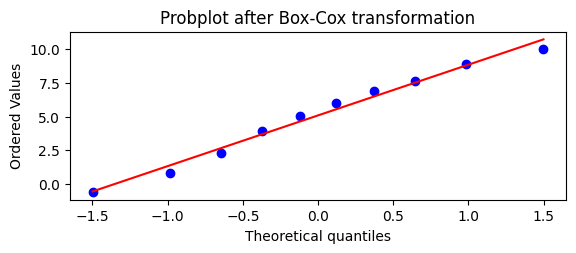

In [74]:
#Gráfico QQ-Plot após a aplicação da transformação
fig = plt.figure()
ax2 = fig.add_subplot(212)
prob = stats.probplot(y_t, dist=stats.norm, plot=ax2)
ax2.set_title('Probplot after Box-Cox transformation')

/tmp/ipykernel_7117/1880501761.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_ex2, hist = False, kde = True,
/home/pedro/Codes/data-science-techniques/.venv/lib/python3.11/site-packages/seaborn/distributions.py:2496: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  kdeplot(**{axis: a}, ax=ax, color=kde_color, **kde_kws)
/tmp/ipykernel_7117/1880501761.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function 

Lambda value used for Transformation: 0.30990359044388566


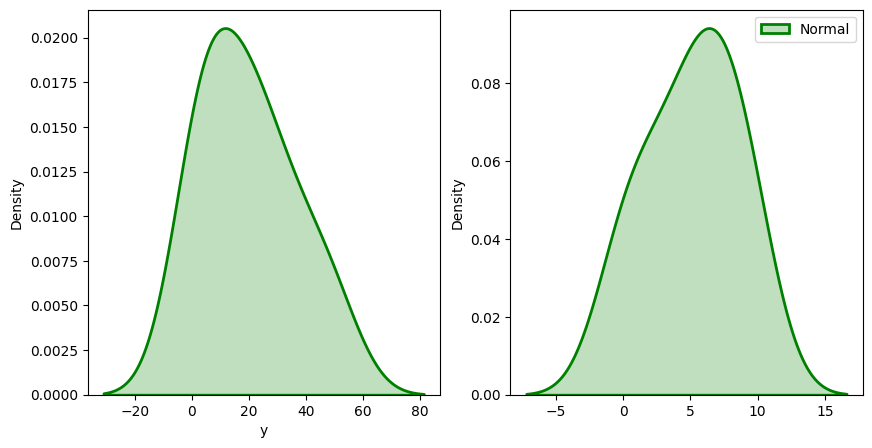

In [75]:
fig, ax = plt.subplots(1, 2)

# plotando os dados originais antes da transformação e os dados transformados
sns.distplot(y_ex2, hist = False, kde = True,
            kde_kws = {'shade': True, 'linewidth': 2},
            label = "Non-Normal", color ="green", ax = ax[0])

sns.distplot(y_t, hist = False, kde = True,
            kde_kws = {'shade': True, 'linewidth': 2},
            label = "Normal", color ="green", ax = ax[1])

# adding legends to the subplots
plt.legend(loc = "upper right")

# rescaling the subplots
fig.set_figheight(5)
fig.set_figwidth(10)

print(f"Lambda value used for Transformation: {lmax_mle}")